In [1]:
import pandas as pd
import numpy as np
import time
from tqdm import tqdm
from collections import defaultdict
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy.special import expit # Sigmoid function

In [2]:
ratings_full = pd.read_csv('../data/processed_full/user_item_processed_data.csv')
user_df = pd.read_csv('../data/processed_full/user_features.csv')
item_df = pd.read_csv('../data/processed_full/item_features.csv')

print("Data simulation complete.")
print("\nRatings Full DF shape:", ratings_full.shape)
print("\nItem Features DF shape:", item_df.shape)
print("\nUser Features DF shape:", user_df.shape)
ratings_full.head(5)

Data simulation complete.

Ratings Full DF shape: (1400102, 109)

Item Features DF shape: (27197, 115)

User Features DF shape: (46660, 115)


,user_id,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,text_emb_0,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,1521,19,1.0,NaN,1.0,NaN,1.0,1.0,NaN,-0.041622,...,0.051783,0.090821,0.023550,-0.028458,0.022709,-0.017830,0.030984,-0.066530,-0.004420,0.022615
1,1524,19,1.0,NaN,NaN,1.0,1.0,NaN,0.6,0.094268,...,0.007869,-0.021458,-0.011069,0.033729,-0.014652,0.031356,0.019260,-0.038565,-0.017441,0.011813
2,1527,19,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.226007,...,0.035656,0.022072,0.031577,-0.085225,-0.019208,0.009750,-0.041887,0.036383,0.069358,0.071002
3,1529,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.026531,...,0.003374,0.041171,0.008375,0.020658,0.000111,-0.012515,-0.019410,-0.014252,0.023997,0.030726
4,1530,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.133377,...,-0.012842,-0.004858,0.077540,-0.057574,0.024631,-0.011781,-0.032293,-0.060140,0.048414,0.012466


In [3]:
# load the model
with open('lightfm_hybrid_model_75e_256d.pkl', 'rb') as f:
    loaded_checkpoint = pickle.load(f)
    
model = loaded_checkpoint['model']
user_id_map = loaded_checkpoint['user_id_map']
item_id_map = loaded_checkpoint['item_id_map']
inv_user_id_map = loaded_checkpoint['inv_user_id_map']
inv_item_id_map = loaded_checkpoint['inv_item_id_map']
user_features = loaded_checkpoint['user_features']
item_features = loaded_checkpoint['item_features']
train_interactions = loaded_checkpoint['train_interactions']
test_interactions = loaded_checkpoint['test_interactions']

/Users/maksiuuuuuuu/miniconda3/envs/recsys_env/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [4]:
k_values = [10, 20, 50, 100]
train_interactions_csr = train_interactions.tocsr()
test_interactions_csr = test_interactions.tocsr()

# Pre-calculate true items for test users (as you did)
true_items_per_user = {
    u: dict(zip(test_interactions_csr[u].indices, test_interactions_csr[u].data))
    for u in range(test_interactions_csr.shape[0]) if test_interactions_csr[u].nnz > 0
}

test_user_indices = list(true_items_per_user.keys())
all_item_indices = np.arange(len(item_id_map))

# --- Accumulators for Metrics ---
ndcg_scores = {k: [] for k in k_values}
hit_counts = {k: 0 for k in k_values}
unique_items_recommended = {k: set() for k in k_values}
recommendation_counts = {k: defaultdict(int) for k in k_values} # For Diversity
total_users_evaluated = 0

# Run Rundom Groups

In [5]:
# --- CONFIGURATION ---
EVAL_POOL_SIZE = 5000   # Large enough to minimize group overlap
N_GROUPS_PER_SIZE = 1000 # Large enough for smooth Confidence Intervals
GROUP_SIZES = [4, 6, 8, 10, 12, 15]
TOP_K = 100

In [6]:
# 1. Select the pool of users
# We filter for users who actually exist in the test set mapping
valid_test_users = list(true_items_per_user.keys())

if len(valid_test_users) > EVAL_POOL_SIZE:
    # Randomly sample without replacement
    eval_user_ids = np.random.choice(valid_test_users, size=EVAL_POOL_SIZE, replace=False)
else:
    eval_user_ids = np.array(valid_test_users)

print(f"Preparing evaluation pool with {len(eval_user_ids)} users...")

Preparing evaluation pool with 5000 users...


In [7]:
# 2. Pre-calculate Scores (Batch Prediction)
# We predict for ALL items for these 5000 users at once.
# Memory usage: 5000 users * 27000 items * 4 bytes ~= 540 MB RAM. Safe.

user_indices_repeat = np.repeat(eval_user_ids, len(item_id_map))
item_indices_tile = np.tile(np.arange(len(item_id_map)), len(eval_user_ids))

print("Running batch prediction (this might take 30-60 seconds)...")
flat_scores = model.predict(
    user_indices_repeat, 
    item_indices_tile, 
    user_features=user_features, 
    item_features=item_features,
    num_threads=12
)

# Reshape to (n_users, n_items)
# Row i corresponds to user eval_user_ids[i]
precalc_scores = flat_scores.reshape(len(eval_user_ids), len(item_id_map))
precalc_scores

Running batch prediction (this might take 30-60 seconds)...


array([[-610.68524, -614.12866, -613.7621 , ..., -614.69226, -613.31085,
        -610.3627 ],
       [-541.8754 , -541.3244 , -542.189  , ..., -542.2773 , -542.3944 ,
        -539.6361 ],
       [-533.87964, -534.39996, -534.62317, ..., -533.07294, -532.0664 ,
        -532.48395],
       ...,
       [-698.8159 , -700.6108 , -698.95953, ..., -701.46405, -699.1241 ,
        -697.2909 ],
       [-542.5147 , -542.96063, -541.0287 , ..., -541.7591 , -542.9088 ,
        -540.7365 ],
       [-621.0717 , -623.22314, -622.93317, ..., -622.39685, -621.88257,
        -620.3949 ]], dtype=float32)

In [8]:
# 3. Pre-calculate Training Masks
# We need to know which items each user has already seen to exclude them.
print("Building training masks...")
train_mask = np.zeros(precalc_scores.shape, dtype=bool)

# We need to map Real User ID -> Index in our precalc matrix (0 to 4999)
pool_id_to_index = {uid: i for i, uid in enumerate(eval_user_ids)}

for real_uid in eval_user_ids:
    matrix_idx = pool_id_to_index[real_uid]
    # Get items seen in training
    seen_items = train_interactions_csr[real_uid].indices
    train_mask[matrix_idx, seen_items] = True

print("Pre-calculation complete. Ready for Simulation.")

Building training masks...
Pre-calculation complete. Ready for Simulation.


In [9]:
def aggregate_scores(group_scores, strategy):
    """
    group_scores: (group_size, n_items) matrix of raw LightFM scores
    """
    n_items = group_scores.shape[1]
    
    if strategy == 'additive':
        # Average utility
        return np.mean(group_scores, axis=0)
    
    elif strategy == 'least_misery':
        # Maximize the minimum satisfaction in the group
        return np.min(group_scores, axis=0)
    
    elif strategy == 'multiplicative':
        # 1. Find Min and Max score for each user in the group
        # axis=1 ensures we look at the user's specific range across all items
        mins = np.min(group_scores, axis=1, keepdims=True)
        maxs = np.max(group_scores, axis=1, keepdims=True)
        
        # 2. Min-Max Normalize to range [0.01, 1.0]
        # We use 0.01 as the floor to strictly avoid log(0) issues without using an arbitrary epsilon
        # This converts "User's Worst Item" -> 0.01 and "User's Best Item" -> 1.0
        norm_scores = (group_scores - mins) / (maxs - mins + 1e-9)
        norm_scores = norm_scores * 0.99 + 0.01
        
        # 3. Sum of Logs (Equivalent to Product of Probabilities)
        return np.sum(np.log(norm_scores), axis=0)
    
    elif strategy == 'approval_voting':
        # 1. Determine Threshold per user
        # We define "Approval" as: Score > User's Mean Score for all items
        # This adapts to users who rate strictly vs leniently
        user_means = np.mean(group_scores, axis=1, keepdims=True)
        
        # 2. Cast Votes (1 if above mean, 0 otherwise)
        votes = (group_scores > user_means).astype(float)
        
        # 3. Sum Votes (Count approvals)
        approval_counts = np.sum(votes, axis=0)
        
        # 4. TIE BREAKER (Crucial!)
        # If two items both have 4 votes, the one with higher raw score sum should win.
        # We add a tiny fraction of the additive score.
        # Normalize raw scores to 0-1 range locally to avoid overpowering the vote count
        raw_sum = np.sum(group_scores, axis=0)
        raw_norm = (raw_sum - raw_sum.min()) / (raw_sum.max() - raw_sum.min() + 1e-9)
        
        return approval_counts + (0.01 * raw_norm)

    return np.mean(group_scores, axis=0)

# Group Eval

In [10]:
results = []
strategies = ['additive', 'multiplicative', 'approval_voting', 'least_misery']

print(f"Starting Simulation: {N_GROUPS_PER_SIZE} groups per size...")

for size in GROUP_SIZES:
    # Use tqdm to track progress
    for _ in tqdm(range(N_GROUPS_PER_SIZE), desc=f"Simulating Size {size}"):
        
        # 1. Sample Group
        # We pick indices from our pool (0 to 4999)
        group_pool_indices = np.random.choice(len(eval_user_ids), size=size, replace=False)
        group_real_ids = eval_user_ids[group_pool_indices]
        
        # 2. Extract Data
        # Shape: (size, n_items)
        group_scores = precalc_scores[group_pool_indices]
        group_masks = train_mask[group_pool_indices]
        
        # 3. Combined Mask (If ANYONE saw it, remove it)
        final_mask = np.any(group_masks, axis=0)
        
        for strat in strategies:
            # 4. Aggregate
            final_scores = aggregate_scores(group_scores, strat)
            
            # 5. Apply Mask (Block seen items)
            final_scores[final_mask] = -np.inf
            
            # 6. Get Top K Items
            # We need indices of the winners
            top_items = np.argsort(-final_scores)[:TOP_K]
            
            # 7. Evaluate (Group nDCG)
            # Calculate nDCG for each member individually, then average
            member_ndcgs = []
            
            for i, user_id in enumerate(group_real_ids):
                true_items = true_items_per_user[user_id]
                
                # Calculate nDCG for this member
                dcg = 0.0
                idcg = 0.0
                
                # DCG part
                for rank, item_idx in enumerate(top_items):
                    if item_idx in true_items:
                        dcg += true_items[item_idx] / np.log2(rank + 2)
                
                # IDCG part (Ideal ranking for this specific user)
                sorted_true = sorted(true_items.values(), reverse=True)
                for rank, val in enumerate(sorted_true[:TOP_K]):
                    idcg += val / np.log2(rank + 2)
                
                ndcg = (dcg / idcg) if idcg > 0 else 0.0
                member_ndcgs.append(ndcg)
            
            # 8. Store Result
            results.append({
                'Group_Size': size,
                'Strategy': strat,
                'nDCG': np.mean(member_ndcgs)
            })

# Create DataFrame
df_results = pd.DataFrame(results)
print("Simulation finished.")

Starting Simulation: 1000 groups per size...


Simulating Size 15: 100%|██████████| 1000/1000 [00:08<00:00, 119.32it/s]


Simulation finished.


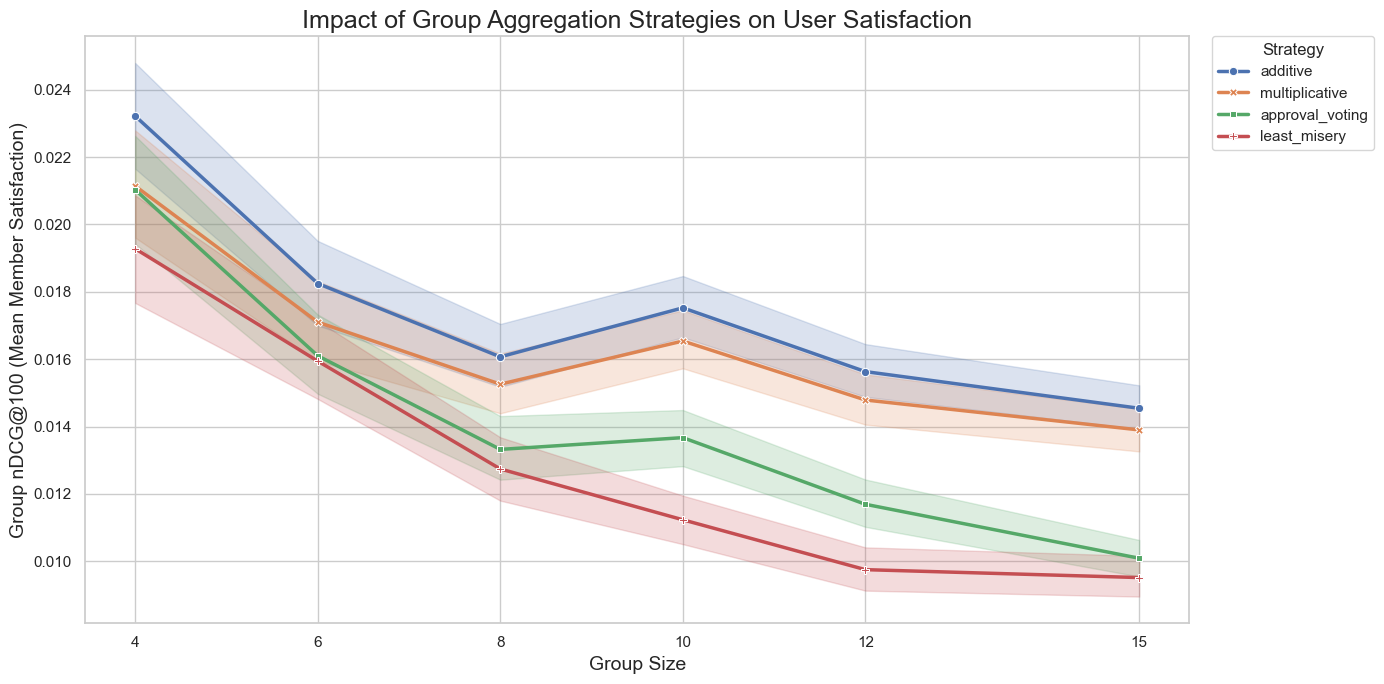


Detailed Statistical Summary:


mean       std  min       max
Group_Size Strategy                                          
4          additive         0.023217  0.027031  0.0  0.183883
           approval_voting  0.021030  0.026522  0.0  0.183883
           least_misery     0.019279  0.024801  0.0  0.155764
           multiplicative   0.021140  0.025603  0.0  0.158309
6          additive         0.018246  0.020149  0.0  0.212371
           approval_voting  0.016100  0.019684  0.0  0.205953
           least_misery     0.015943  0.018508  0.0  0.101758
           multiplicative   0.017100  0.019367  0.0  0.211850
8          additive         0.016069  0.015583  0.0  0.103044
           approval_voting  0.013321  0.014722  0.0  0.106245
           least_misery     0.012741  0.014826  0.0  0.094793
           multiplicative   0.015257  0.015101  0.0  0.113095
10         additive         0.017524  0.014207  0.0  0.087235
           approval_voting  0.013670  0.013032  0.0  0.081168
           least_misery     0.011231  0.012065  0.0  0.083424
           multiplicative   0.016539  0.013810  0.0  0.089386
12         additive         0.015631  0.012798  0.0  0.085767
           approval_voting  0.011692  0.011538  0.0  0.082305
           least_misery     0.009751  0.010354  0.0  0.082131
           multiplicative   0.014788  0.012144  0.0  0.082126
15         additive         0.014542  0.010097  0.0  0.060922
           approval_voting  0.010089  0.008934  0.0  0.061041
           least_misery     0.009516  0.009804  0.0  0.067768
           multiplicative   0.013899  0.009914  0.0  0.058690

In [11]:
import matplotlib.pyplot as plt
# Set up plotting
sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(14, 7))

# Draw Box Plot + Swarm or simple Bar with Error Bars
# Using Lineplot is often cleaner for "Size vs Performance" comparison
ax = sns.lineplot(
    data=df_results, 
    x="Group_Size", 
    y="nDCG", 
    hue="Strategy",
    style="Strategy",
    markers=True,
    dashes=False,
    linewidth=2.5,
    errorbar=('ci', 95) # 95% Confidence Interval shading
)

plt.title("Impact of Group Aggregation Strategies on User Satisfaction", fontsize=18)
plt.ylabel("Group nDCG@100 (Mean Member Satisfaction)", fontsize=14)
plt.xlabel("Group Size", fontsize=14)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Strategy")
plt.xticks(GROUP_SIZES)
plt.tight_layout()
plt.show()

# --- Statistical Table ---
summary = df_results.groupby(['Group_Size', 'Strategy'])['nDCG'].describe()[['mean', 'std', 'min', 'max']]
print("\nDetailed Statistical Summary:")
display(summary)

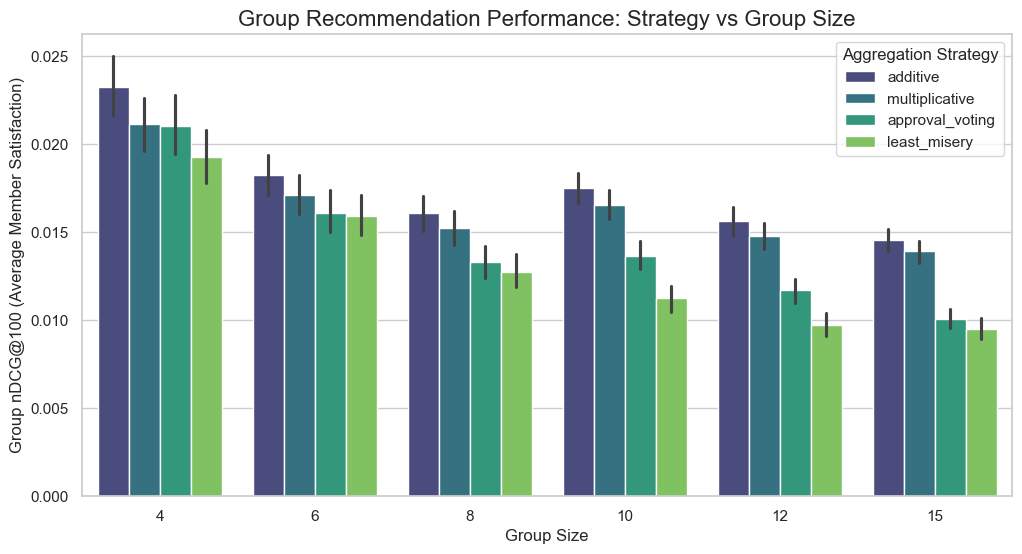


Mean nDCG Scores:


Strategy,additive,approval_voting,least_misery,multiplicative
Group_Size,,,,
4,0.023217,0.021030,0.019279,0.021140
6,0.018246,0.016100,0.015943,0.017100
8,0.016069,0.013321,0.012741,0.015257
10,0.017524,0.013670,0.011231,0.016539
12,0.015631,0.011692,0.009751,0.014788
15,0.014542,0.010089,0.009516,0.013899


In [12]:
# Set plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Create Barplot
# ci=95 draws the confidence intervals (error bars) automatically
ax = sns.barplot(
    data=df_results, 
    x="Group_Size", 
    y="nDCG", 
    hue="Strategy", 
    palette="viridis",
    errorbar=('ci', 95) 
)

plt.title("Group Recommendation Performance: Strategy vs Group Size", fontsize=16)
plt.ylabel("Group nDCG@100 (Average Member Satisfaction)", fontsize=12)
plt.xlabel("Group Size", fontsize=12)
plt.legend(title="Aggregation Strategy", loc='upper right')
plt.show()

# Print numerical summary
summary = df_results.groupby(['Group_Size', 'Strategy'])['nDCG'].mean().unstack()
print("\nMean nDCG Scores:")
display(summary)